# Assignment 14: DINOv2 Self-Supervised ViT Embeddings & Nearest-Prototype Few-Shot Classification
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course  
**Model:** Meta AI `DINOv2` (`dinov2_vits14`)

This project implements metric learning and few-shot prototype classification on handwriting variations:
1. **Connected Component Image Segmentation:** Isolating individual handwritten digits from scanned sheets using OpenCV morphology and connected components.
2. **Self-Supervised Feature Extraction:** Feeding normalized image crops into Meta's self-supervised `DINOv2-ViT` to generate semantic feature embeddings without fine-tuning.
3. **Nearest Centroid Prototype Classification:** Selecting small prototypical support sets for fine stylistic variants (European sevens with crossbars vs plain sevens) and classifying the entire dataset via vector distance in embedding space.


--2026-03-18 13:10:22--  https://www.agentspace.org/download/sevens.png
Resolving www.agentspace.org (www.agentspace.org)... 62.168.101.9
Connecting to www.agentspace.org (www.agentspace.org)|62.168.101.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 866523 (846K) [image/png]
Saving to: ‘sevens.png.1’

sevens.png.1        100%[===================>] 846.21K  1.03MB/s    in 0.8s    

2026-03-18 13:10:24 (1.03 MB/s) - ‘sevens.png.1’ saved [866523/866523]



Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Total digits detected: 500


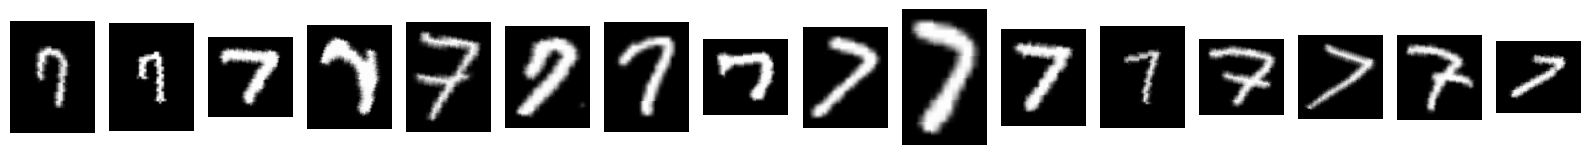

------------------------------
RESULT (DINOv2):
Total sevens      : 500
With crossbar     : 66
Without crossbar  : 434
------------------------------


In [2]:
# ── Setup & Model Loading ─────────────────────────────────────────────────────
!wget https://www.agentspace.org/download/sevens.png

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

hw = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dino = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(hw)
dino.eval()

normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# ── Segmentation ──────────────────────────────────────────────────────────────
src = cv2.imread('sevens.png')
grayscale = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)
_, thresholded = cv2.threshold(grayscale, 180, 255, cv2.THRESH_BINARY)
dilated = cv2.dilate(thresholded, None, iterations=7)

num_labels, label_map, stat_table, _ = cv2.connectedComponentsWithStats(dilated, connectivity=8)

padding = 5
digits = []
for label_id in range(1, num_labels):
    lx, ly, lw, lh = stat_table[label_id, :4]
    crop = src[max(0, ly-padding):ly+lh+padding, max(0, lx-padding):lx+lw+padding]
    digits.append(crop)

print(f"Total digits detected: {len(digits)}")

# ── Preview first 16 ──────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 16, figsize=(16, 2))
for ax, img in zip(axes, digits[:16]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.tight_layout()
plt.show()

# ── Embedding Extraction ──────────────────────────────────────────────────────
feature_vectors = []
with torch.no_grad():
    for digit_bgr in digits:
        rgb     = cv2.cvtColor(digit_bgr, cv2.COLOR_BGR2RGB)
        tensor  = normalize(Image.fromarray(rgb)).unsqueeze(0).to(hw)
        vec     = dino(tensor)
        feature_vectors.append(vec.cpu().numpy().flatten())

feature_vectors = np.array(feature_vectors)



# ── Prototype Indices (adjust based on preview above) ─────────────────────────
plain_samples   = [0, 1, 2, 10, 13]   # sevens WITHOUT crossbar
crossed_samples = [4, 12, 14, 22]     # sevens WITH crossbar

# ── Nearest-Prototype Classification ─────────────────────────────────────────
centroid_plain   = feature_vectors[plain_samples].mean(axis=0)
centroid_crossed = feature_vectors[crossed_samples].mean(axis=0)

struck = sum(
    1 for vec in feature_vectors
    if np.linalg.norm(vec - centroid_crossed) < np.linalg.norm(vec - centroid_plain)
)

# ── Results ───────────────────────────────────────────────────────────────────
print("-" * 30)
print("RESULT (DINOv2):")
print(f"Total sevens      : {len(digits)}")
print(f"With crossbar     : {struck}")
print(f"Without crossbar  : {len(digits) - struck}")
print("-" * 30)